In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
from pathlib import Path
import pandas as pd

file_path = Path(
    r"C:\Users\Akash\StreamFlix_Project\streamflix.xlsx"
)

print("File exists:", file_path.exists())

File exists: True


In [4]:
data = pd.read_excel(file_path, sheet_name=None)

print("Excel file imported successfully!")
print("Available sheets:", list(data.keys()))

Excel file imported successfully!
Available sheets: ['watchlist', 'watch_history', 'titles', 'subscribers', 'reviews', 'ratings']


In [5]:

#separate DataFrames

subscribers = data["subscribers"]
titles = data["titles"]
watch_history = data["watch_history"]
ratings = data["ratings"]
reviews = data["reviews"]
watchlist = data["watchlist"]

print("All six tables are ready!")

for name, df in data.items():
    print(name, df.shape)


All six tables are ready!
watchlist (65000, 5)
watch_history (650000, 10)
titles (9000, 21)
subscribers (15000, 14)
reviews (110000, 7)
ratings (130000, 5)


In [8]:

#Convert date columns

date_columns = {
    "subscribers": ["signup_date", "churn_date"],
    "titles": ["date_added", "license_expiry"],
    "watch_history": ["watch_date"],
    "ratings": ["rating_date"],
    "reviews": ["review_date"],
    "watchlist": ["added_date"]
}

for table_name, columns in date_columns.items():
    for column in columns:
        data[table_name][column] = pd.to_datetime(
            data[table_name][column],
            errors="coerce"
        )

print("Date columns converted successfully!")

#Check viewing date range
print("First viewing date:", watch_history["watch_date"].min())
print("Last viewing date:", watch_history["watch_date"].max())


Date columns converted successfully!
First viewing date: 2017-03-10 00:00:00
Last viewing date: 2026-05-31 00:00:00


In [7]:

#Import chart libraries

import matplotlib.pyplot as plt
from pathlib import Path

output_folder = Path("Phase2_Charts")
output_folder.mkdir(exist_ok=True)

print("Charts folder:", output_folder.resolve())


Charts folder: C:\Users\Akash\StreamFlix_Project\Phase2_Charts


Busiest month: May 2026
Sessions: 224,696


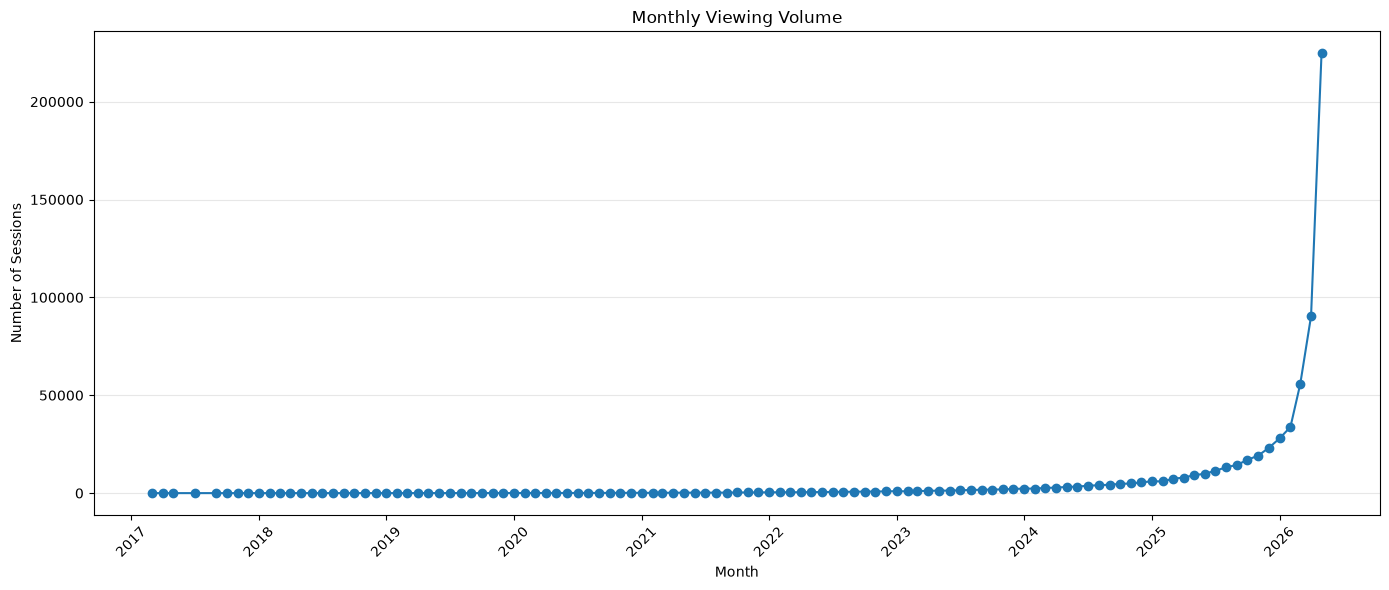

In [8]:

# Chart 1: Monthly Viewing Volume

monthly_sessions = (
    watch_history.dropna(subset=["watch_date"])
    .groupby(watch_history["watch_date"].dropna().dt.to_period("M"))
    .size()
    .sort_index()
)

monthly_sessions.index = monthly_sessions.index.to_timestamp()

print("Busiest month:", monthly_sessions.idxmax().strftime("%B %Y"))
print("Sessions:", f"{monthly_sessions.max():,}")

plt.figure(figsize=(14, 6))
plt.plot(monthly_sessions.index, monthly_sessions.values, marker="o")

plt.title("Monthly Viewing Volume")
plt.xlabel("Month")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(output_folder / "01_monthly_viewing_volume.png", dpi=300)
plt.show()


**Observation — Monthly Viewing Volume**

Viewing sessions increased gradually over time, with a very sharp rise in the latest months. The highest point appears in May 2026, but this sudden increase is unusually large compared with previous months and should be checked for possible data-quality issues.

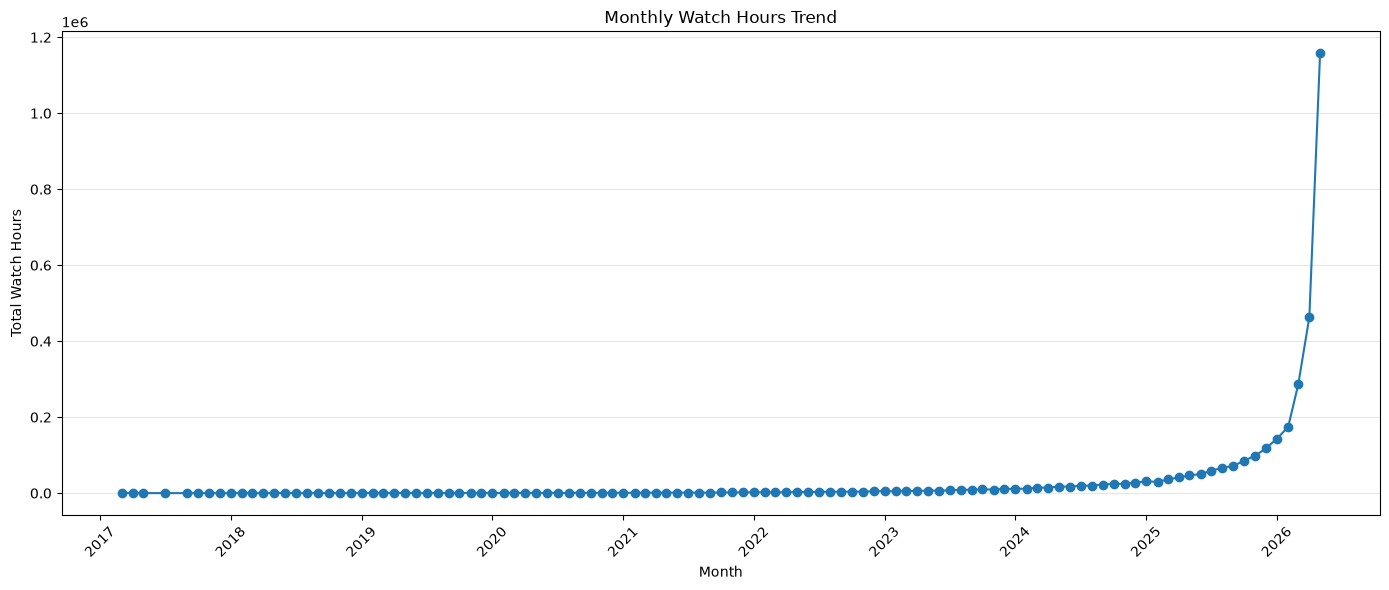

Total watch hours: 3333467.73


In [9]:

# Chart 2: Monthly Watch Hours Trend

watch_history["watch_hours"] = (
    watch_history["watch_duration_min"] / 60
)

monthly_hours = (
    watch_history.dropna(subset=["watch_date"])
    .groupby(watch_history["watch_date"].dropna().dt.to_period("M"))["watch_hours"]
    .sum()
    .sort_index()
)

monthly_hours.index = monthly_hours.index.to_timestamp()

plt.figure(figsize=(14, 6))
plt.plot(monthly_hours.index, monthly_hours.values, marker="o")

plt.title("Monthly Watch Hours Trend")
plt.xlabel("Month")
plt.ylabel("Total Watch Hours")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(output_folder / "02_monthly_watch_hours.png", dpi=300)
plt.show()

print("Total watch hours:", round(monthly_hours.sum(), 2))


**Observation: Monthly Watch Hours Trend**

The monthly watch-hours trend follows a pattern similar to viewing volume, with a sharp increase toward the end of the timeline. The latest month shows a much higher number of watch hours than earlier months, so the data should be checked before treating this as genuine growth in viewer engagement.

In [10]:

# Year-wise watch hours

yearly_hours = (
    watch_history.dropna(subset=["watch_date"])
    .groupby(watch_history["watch_date"].dropna().dt.year)["watch_hours"]
    .sum()
)

print("Year-wise watch hours:")
display(yearly_hours.round(2).to_frame("Total Watch Hours"))


Year-wise watch hours:


,Total Watch Hours
watch_date,
2017,45.76
2018,583.54
2019,1679.41
2020,5471.78
2021,15435.33
2022,37353.96
2023,89665.82
2024,223994.05
2025,733939.06


Top genre: Drama
Watch hours: 501884.47


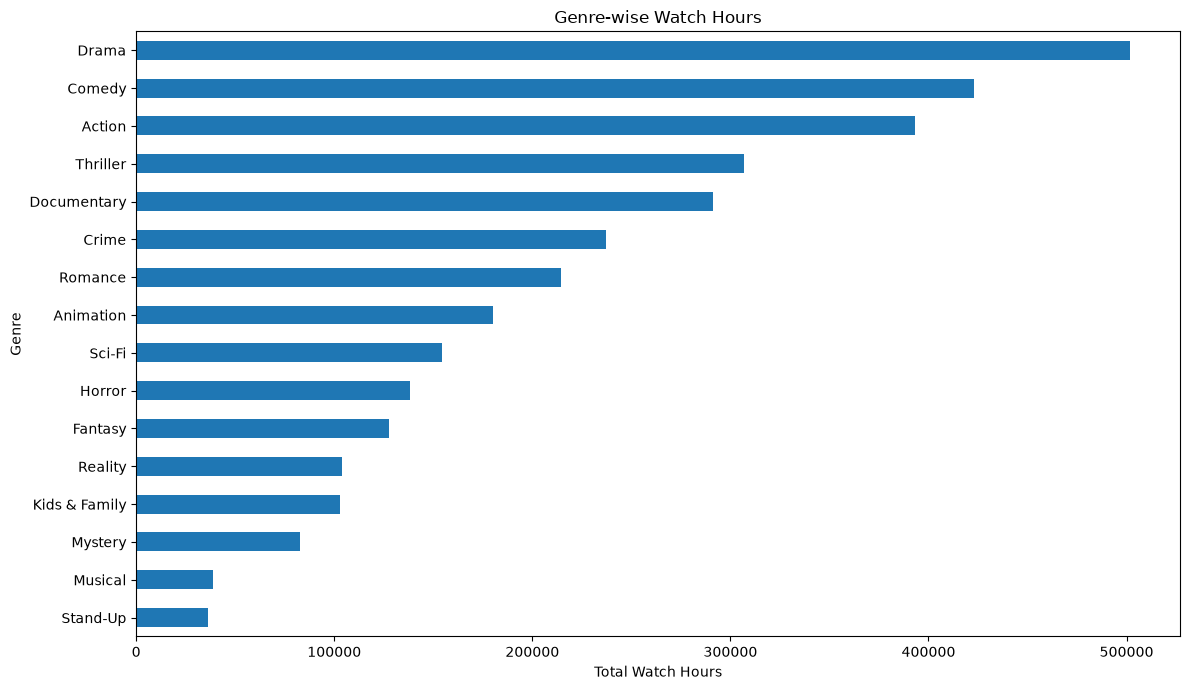

In [11]:

# Chart 3: Genre-wise Watch Hours

genre_data = watch_history.merge(
    titles[["title_id", "primary_genre"]],
    on="title_id",
    how="left",
    validate="many_to_one"
)

genre_hours = (
    genre_data.groupby("primary_genre")["watch_hours"]
    .sum()
    .sort_values(ascending=False)
)

print("Top genre:", genre_hours.idxmax())
print("Watch hours:", round(genre_hours.max(), 2))

plt.figure(figsize=(12, 7))
genre_hours.sort_values().plot(kind="barh")

plt.title("Genre-wise Watch Hours")
plt.xlabel("Total Watch Hours")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig(output_folder / "03_genre_watch_hours.png", dpi=300)
plt.show()


**Observation: Genre-wise Watch Hours**

Drama has the highest total watch hours, followed by Comedy and Action. Stand-Up and Musical have the lowest watch hours among the genres shown, indicating that viewing time is concentrated more heavily in some genres than others.

Content type watch hours:


,Watch Hours
type,
Tv Show,2.882609e+06
Movie,4.508588e+05


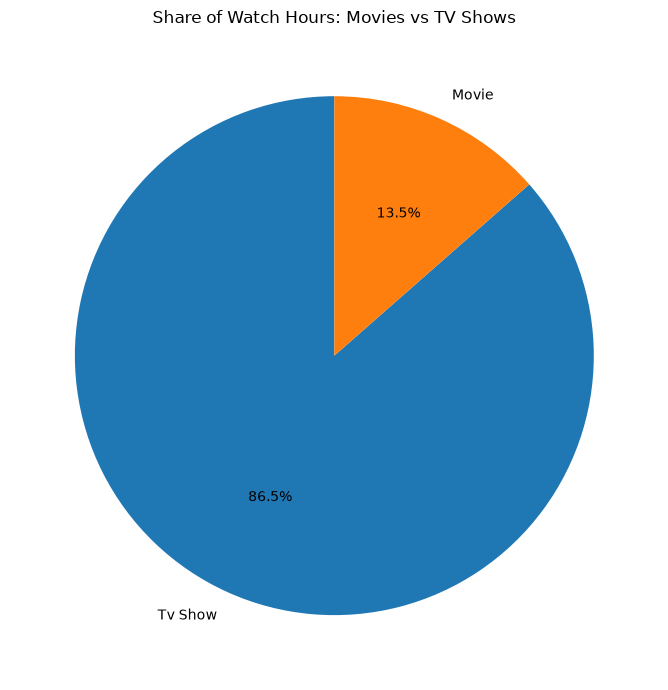

In [9]:



# Chart 4: Chart 4: Movies vs TV Shows
possible_columns = [
    "type",
    "content_type",
    "title_type",
    "program_type"
]

type_column = next(
    (col for col in possible_columns if col in titles.columns),
    None
)

if type_column is None:
    print("Content type column nahi mila.")
    print("Available columns:", titles.columns.tolist())

else:
# Merge content type into watch history
    type_data = watch_history.merge(
        titles[["title_id", type_column]],
        on="title_id",
        how="left",
        validate="many_to_one"
    )

 # Calculate watch hours by content type
    type_data["watch_hours"] = pd.to_numeric(
        type_data["watch_hours"]
        if "watch_hours" in type_data.columns
        else type_data["watch_duration_min"] / 60,
        errors="coerce"
    )

    type_hours = (
        type_data.groupby(type_column)["watch_hours"]
        .sum()
        .sort_values(ascending=False)
    )

    print("Content type watch hours:")
    display(type_hours.to_frame("Watch Hours"))

# Create pie chart
    plt.figure(figsize=(7, 7))

    plt.pie(
        type_hours,
        labels=type_hours.index,
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("Share of Watch Hours: Movies vs TV Shows")
    plt.tight_layout()

    plt.savefig(
        output_folder / "04_content_type_split.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()



**Observation: Movies vs TV Shows**

TV Shows account for 86.5% of total watch hours, while Movies contribute 13.5%. This shows that TV Shows generate a much larger share of viewing time on StreamFlix.

Top 10 countries:


,Watch Hours
country,
United States,910551.198333
India,380917.681667
United Kingdom,285346.350000
South Korea,239498.930000
Brazil,206648.200000
Japan,171707.983333
France,167418.188333
Mexico,143971.786667
Spain,137107.413333


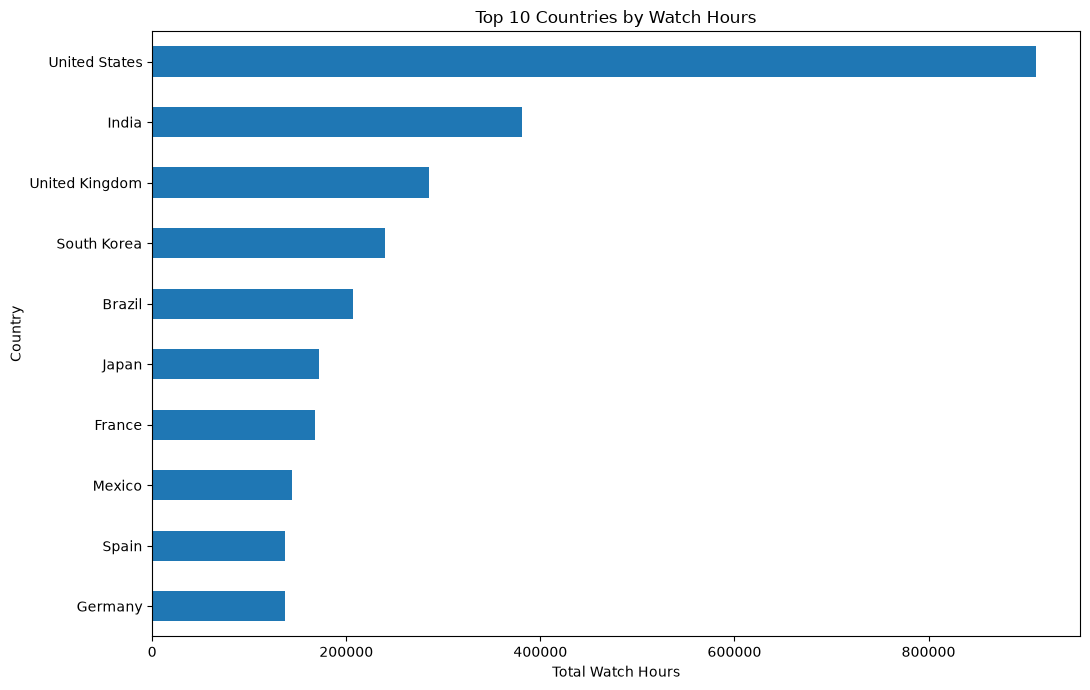

In [18]:

# Chart 5: Top 10 Countries by Watch Hours

country_data = watch_history.merge(
    subscribers[["subscriber_id", "country"]],
    on="subscriber_id",
    how="left",
    validate="many_to_one"
)

country_hours = (
    country_data.groupby("country")["watch_hours"]
    .sum()
    .nlargest(10)
)

print("Top 10 countries:")
display(country_hours.to_frame("Watch Hours"))

plt.figure(figsize=(11, 7))
country_hours.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Watch Hours")
plt.xlabel("Total Watch Hours")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig(output_folder / "05_top_10_countries.png", dpi=300)
plt.show()


**Observation: Top 10 Countries by Watch Hours**

The United States has the highest total watch hours by a considerable margin, followed by India and the United Kingdom. South Korea and Brazil are also among the top five countries, showing that viewing activity is spread across several international markets.

Subscriber count by plan:


,Subscribers
plan_type,
Standard,6100
Basic With Ads,4458
Premium,4442


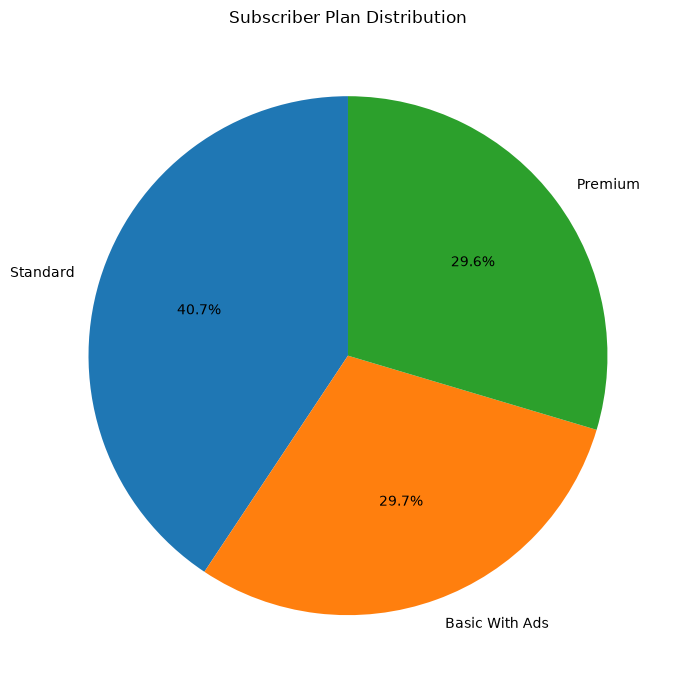

In [19]:

# Chart 6: Subscriber Plan Distribution

plan_counts = subscribers["plan_type"].value_counts()

print("Subscriber count by plan:")
display(plan_counts.to_frame("Subscribers"))

plt.figure(figsize=(7, 7))
plt.pie(
    plan_counts,
    labels=plan_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Subscriber Plan Distribution")
plt.tight_layout()

plt.savefig(output_folder / "06_subscriber_plan_distribution.png", dpi=300)
plt.show()


**Observation: Subscriber Plan Distribution**

The Standard plan has the largest share of subscribers at 40.7%. Basic with Ads and Premium account for 29.7% and 29.6%, respectively, so the subscriber distribution is fairly balanced between these two plans.

Sessions by device:


,Sessions
device,
Smart Tv,221446
Mobile,175605
Laptop,96408
Tablet,65276
Game Console,52322
Streaming Stick,38943


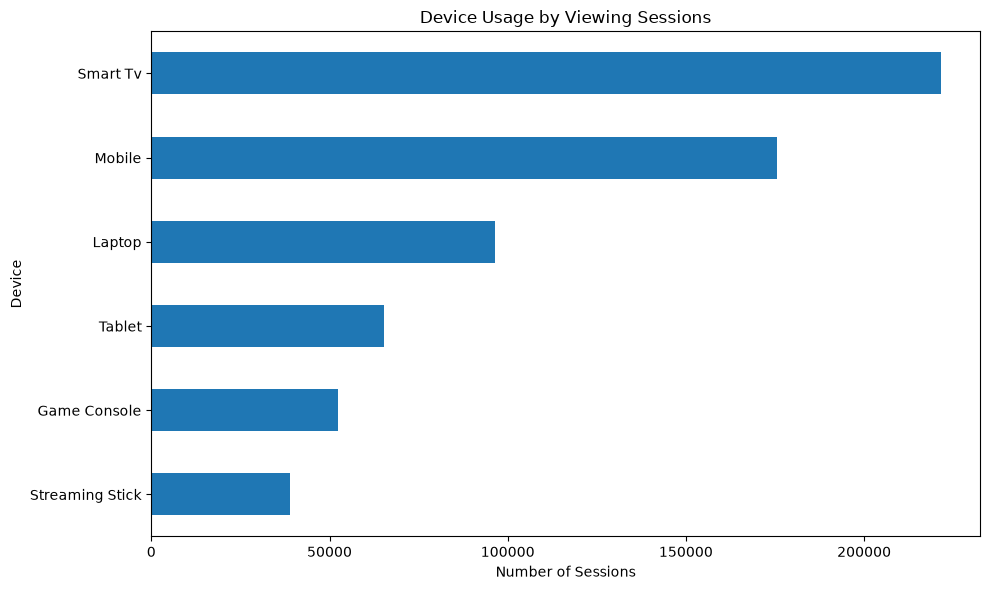

In [20]:

# Chart 7: Device Usage

device_counts = watch_history["device"].value_counts()

print("Sessions by device:")
display(device_counts.to_frame("Sessions"))

plt.figure(figsize=(10, 6))
device_counts.sort_values().plot(kind="barh")

plt.title("Device Usage by Viewing Sessions")
plt.xlabel("Number of Sessions")
plt.ylabel("Device")
plt.tight_layout()

plt.savefig(output_folder / "07_device_usage.png", dpi=300)
plt.show()


**Observation: Device Usage**

Smart TVs are the most frequently used devices for viewing content, followed by Mobile devices. Streaming Sticks have the fewest viewing sessions among the devices shown, suggesting that subscribers use some devices much more frequently than others.

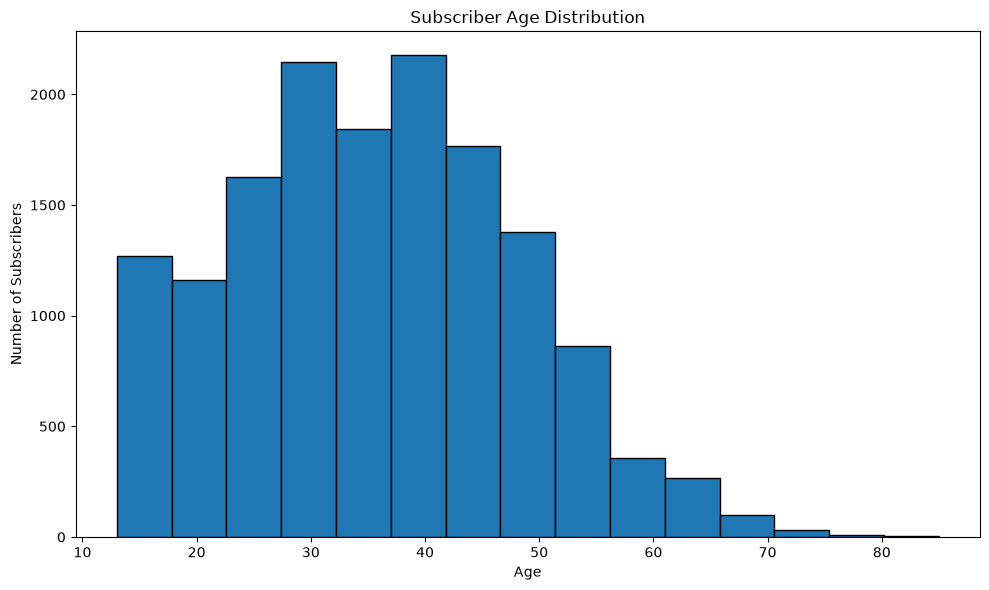

Average age: 35.62
Median age: 35.0


In [21]:

# Chart 8: Subscriber Age Distribution

ages = subscribers["age"].dropna()

plt.figure(figsize=(10, 6))
plt.hist(ages, bins=15, edgecolor="black")

plt.title("Subscriber Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Subscribers")
plt.tight_layout()

plt.savefig(output_folder / "08_age_distribution.png", dpi=300)
plt.show()

print("Average age:", round(ages.mean(), 2))
print("Median age:", round(ages.median(), 2))


**Observation: Subscriber Age Distribution**

Most subscribers fall within the approximate age range of 25 to 45, with the highest concentrations around the early 30s and late 30s. Subscriber counts decrease at older ages, particularly after 50, indicating that the platform's subscriber base is more concentrated among younger and middle-aged adults.

In [22]:

# Extra: Watch hours by subscriber age group

age_data = watch_history.merge(
    subscribers[["subscriber_id", "age"]],
    on="subscriber_id",
    how="left",
    validate="many_to_one"
)

age_data["age_group"] = pd.cut(
    age_data["age"],
    bins=[12, 18, 25, 35, 45, 55, 65, 86],
    labels=[
        "13-17", "18-24", "25-34", "35-44",
        "45-54", "55-64", "65-85"
    ],
    right=False
)

age_hours = age_data.groupby(
    "age_group", observed=False
)["watch_hours"].sum()

display(age_hours.sort_values(ascending=False).to_frame("Watch Hours"))


,Watch Hours
age_group,
35-44,972656.506667
25-34,890783.301667
45-54,603302.266667
18-24,358171.958333
13-17,281924.236667
55-64,192413.080000
65-85,34216.383333


Average completion percentage by genre:


,Average Completion %
primary_genre,
Musical,66.83
Animation,66.38
Stand-Up,66.32
Fantasy,65.97
Sci-Fi,65.79
Mystery,65.56
Crime,65.46
Comedy,65.32
Kids & Family,65.31


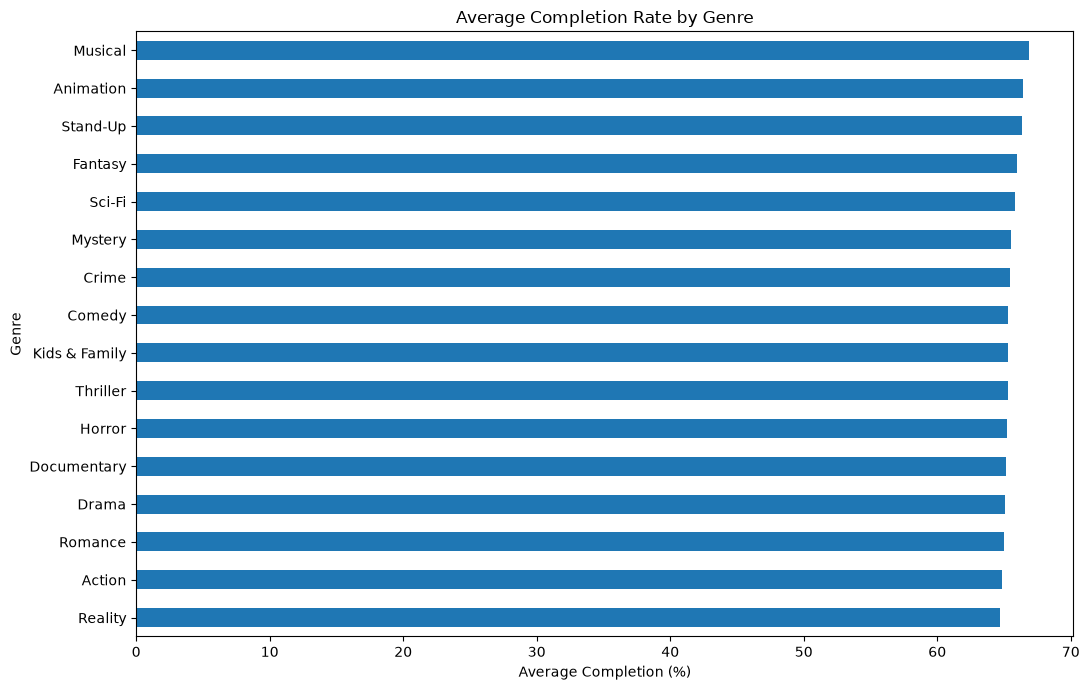

In [23]:

# Chart 9: Completion Rate by Genre

completion_data = watch_history.merge(
    titles[["title_id", "primary_genre"]],
    on="title_id",
    how="left",
    validate="many_to_one"
)

genre_completion = (
    completion_data.groupby("primary_genre")["completion_pct"]
    .mean()
    .dropna()
    .sort_values(ascending=False)
)

print("Average completion percentage by genre:")
display(genre_completion.round(2).to_frame("Average Completion %"))

plt.figure(figsize=(11, 7))
genre_completion.sort_values().plot(kind="barh")

plt.title("Average Completion Rate by Genre")
plt.xlabel("Average Completion (%)")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig(output_folder / "09_completion_by_genre.png", dpi=300)
plt.show()


**Observation: Completion Rate by Genre**

Average completion rates are relatively similar across all genres, with most values falling between approximately 65% and 67%. Musical has the highest completion rate, while Reality has the lowest, although the difference between genres is small.

Review sentiment counts:


,Review Count
sentiment,
Positive,75007
Neutral,22759
Negative,12234


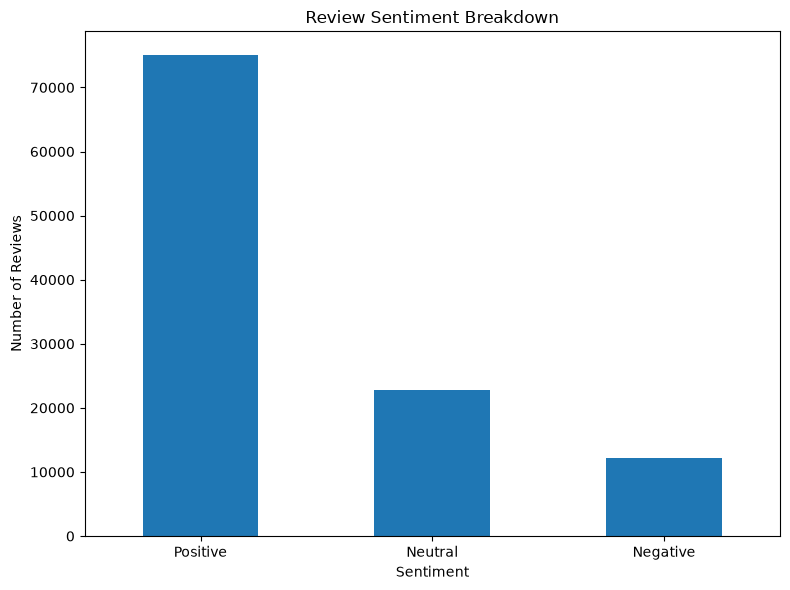

In [24]:

# Chart 10: Review Sentiment Breakdown

sentiment_counts = (
    reviews["sentiment"]
    .value_counts()
    .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
)

print("Review sentiment counts:")
display(sentiment_counts.to_frame("Review Count"))

plt.figure(figsize=(8, 6))
sentiment_counts.plot(kind="bar")

plt.title("Review Sentiment Breakdown")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(output_folder / "10_review_sentiment.png", dpi=300)
plt.show()


**Observation: Review Sentiment Breakdown**

Positive reviews are the most common, with approximately 75,000 reviews, followed by Neutral reviews at around 23,000 and Negative reviews at around 12,000. Overall, the distribution is strongly weighted toward positive feedback, although the neutral and negative reviews can still help identify areas for improvement.